# BO1 — Sécurité routière : détection des anomalies par architectures alternatives
**Projet : RoadAnomaly — FCN scratch, Mask R-CNN scratch, FCN-ResNet50 pré-entraîné**  
**Source unique :** archive `RoadAnomaly-main(2).zip`. Aucun dataset externe.  
**Attention :** le notebook contient l'intégralité du pipeline, mais les entraînements lourds ne sont pas pré-exécutés. Les cellules produisent les résultats réels lors de leur exécution.

**Différence avec le travail déjà réalisé :** pas de U-Net ResNet34 ni de simple encodeur-décodeur CNN comme modèle principal. Deux familles du cours : **FCN** (segmentation sémantique) et **Mask R-CNN** (segmentation d'instances). Les trois expériences sont (1) FCN scratch, (2) Mask R-CNN scratch, (3) FCN avec backbone ResNet50 pré-entraîné. La troisième architecture est un FCN ; son encodeur ResNet50 est une variante de ResNet, famille étudiée en cours. Si le professeur impose des architectures toutes différentes, les expériences 1 et 3 restent deux initialisations d'une même famille, ce qui doit être annoncé.

## 1. Business Understanding
**Problème :** un système d'aide à la conduite doit signaler des anomalies visibles sur la chaussée.  
**Use case :** sur une image issue d'une caméra embarquée, identifier les régions anormales et afficher une **alerte visuelle indicative**. Mask R-CNN distingue potentiellement plusieurs instances ; FCN produit une carte binaire des anomalies.  
**Utilisateurs :** chercheurs en perception routière et développeurs de prototypes ADAS.  
**Critère principal :** **rappel des pixels d'anomalie** (ne pas manquer les pixels dangereux), accompagné de l'IoU, Dice, précision et temps d'inférence. Le rappel pixel n'est **pas** un taux de détection d'obstacles : mesurer aussi le rappel par composante est utile.  
**Limites :** aucune distance, vitesse, gravité, trajectoire ou décision de freinage n'est calculée. Les images seules ne démontrent aucune sûreté en conditions réelles. Les scores ne sont pas garantis.

In [1]:
# Installation optionnelle (décommenter seulement si nécessaire dans Colab/Jupyter)
# %pip install -q torch torchvision pillow numpy pandas matplotlib scikit-learn opencv-python nbformat
import os, sys, json, random, time, zipfile, hashlib, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import cv2, torch, torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python',sys.version.split()[0],'Torch',torch.__version__,'Torchvision',torchvision.__version__,'Device',DEVICE)

Python 3.12.7 Torch 2.15.0+cpu Torchvision 0.29.2+cpu Device cpu


## 2. Data Understanding — inspection réelle et provenance
Le jeu de données contient des images WebP, des masques sémantiques, des masques d'instances et des fichiers internes d'annotation. **Ne pas confondre** `labels_semantic.png` (classes), `labels_instance.png` (instances), `labels_semantic_color.png` (visualisation) et les fichiers de l'éditeur. Les crédits/licences des images sont dans `credits.txt` ; les annotations y sont indiquées CC BY-SA 4.0. Les images ont des crédits distincts : consulter le fichier avant redistribution.

In [2]:
from pathlib import Path

# Compatible avec VS Code : dataset déjà extrait, sans ZIP obligatoire.
HERE = Path.cwd().resolve()
CANDIDATES = [
    HERE / "RoadAnomaly",
    HERE,
    HERE / "RoadAnomaly-main" / "RoadAnomaly",
    HERE.parent / "RoadAnomaly",
]
DATA = next((p for p in CANDIDATES if (p / "frames").is_dir()), None)
if DATA is None:
    raise FileNotFoundError(
        f"Dossier frames introuvable depuis {HERE}. "
        "Ouvre le projet RoadAnomaly-main dans VS Code."
    )
FRAMES = DATA / "frames"
images = sorted(FRAMES.glob("*.webp"))
masks = sorted(FRAMES.glob("*.labels/labels_semantic.png"))
print("Dataset :", DATA.resolve())
print("Images :", len(images), "| Masques sémantiques :", len(masks))
print("Masques d'instances disponibles :", len(list(FRAMES.glob("*.labels/labels_instance.png"))))
print("Notebooks :", [p.name for p in DATA.glob("*.ipynb")])
credits_path = DATA / "credits.txt"
if credits_path.exists():
    print("Crédits (extrait) :", credits_path.read_text(encoding="utf-8", errors="replace")[:550])
assert images, "Aucune image .webp trouvée"
assert masks, "Aucun masque labels_semantic.png trouvé"


Dataset : C:\Users\arije\Downloads\RoadAnomaly-main\RoadAnomaly-main\RoadAnomaly
Images : 60 | Masques sémantiques : 60
Masques d'instances disponibles : 46
Notebooks : ['BO1_RoadAnomaly_VERSION_FINALE_AMELIOREE.ipynb', 'poject.ipynb']
Crédits (extrait) : 
The images are provided for research purposes.
We do not own the images; the authors and sources are listed below.

The annotations (labels) are under CC BY-SA 4.0 https://creativecommons.org/licenses/by-sa/4.0/


animals01_Guiguinto_railway_station_Calves
	Florentino Floro, CC0 https://creativecommons.org/publicdomain/zero/1.0/deed.en
	https://commons.wikimedia.org/wiki/File:03167JfGuiguinto_railway_station_Calves_grasslands_Tabe_Tuktukan_Calves_Roadsfvf_07.jpg

animals04_17_animal_casualties_so_far_in_2006
	Nigel Freeman, CC BY-SA 2.0 https:


In [3]:
records=[]; bad_files=[]; mask_values=set(); hashes={}
for ip in images:
    mp=FRAMES/(ip.stem+'.labels')/'labels_semantic.png'
    inst=FRAMES/(ip.stem+'.labels')/'labels_instance.png'
    try:
        with Image.open(ip) as im: rgb=np.array(im.convert('RGB')); mode=im.mode
        with Image.open(mp) as im: mask=np.array(im)
        assert mask.ndim==2, f'Masque non indexé {mask.shape}'
        assert mask.shape==rgb.shape[:2], 'Dimensions non concordantes'
        vals=np.unique(mask); mask_values.update(vals.tolist())
        h=hashlib.sha256(ip.read_bytes()).hexdigest(); hashes.setdefault(h,[]).append(ip.name)
        records.append(dict(image=str(ip),mask=str(mp),instance=str(inst),name=ip.name,width=rgb.shape[1],height=rgb.shape[0],mode=mode,values=str(vals.tolist()),anomaly_px=int((mask==2).sum()),area_ratio=float((mask==2).mean())))
    except Exception as e: bad_files.append((ip.name,str(e)))
df=pd.DataFrame(records)
print('Valeurs des masques:',sorted(mask_values),'Fichiers défectueux:',bad_files)
print('Doublons SHA256 exacts:',[v for v in hashes.values() if len(v)>1])
print('Tailles:',df[['width','height']].describe())
print('Masques d’instances absents :',sum(not Path(p).exists() for p in df['instance']))
print('Ratio de surface:',df.area_ratio.describe())
assert 2 in mask_values,'La valeur 2 ne correspond pas aux masques inspectés : vérifier avant de poursuivre'
assert len(df)>0

Valeurs des masques: [0, 2] Fichiers défectueux: []
Doublons SHA256 exacts: []
Tailles:         width  height
count    60.0    60.0
mean   1280.0   720.0
std       0.0     0.0
min    1280.0   720.0
25%    1280.0   720.0
50%    1280.0   720.0
75%    1280.0   720.0
max    1280.0   720.0
Masques d’instances absents : 14
Ratio de surface: count    60.000000
mean      0.098496
std       0.100600
min       0.003747
25%       0.018016
50%       0.066229
75%       0.137958
max       0.423286
Name: area_ratio, dtype: float64


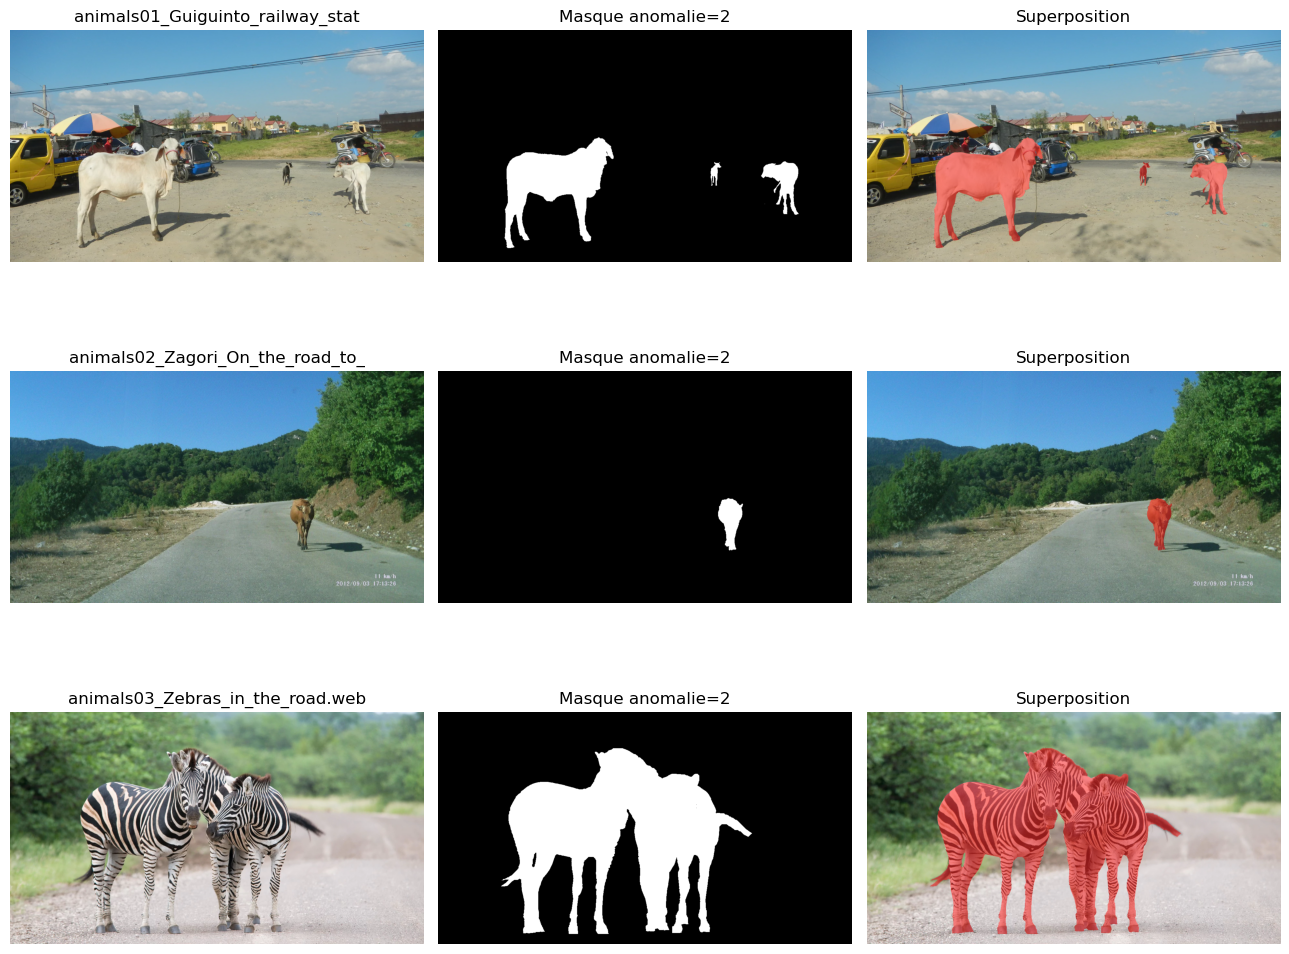

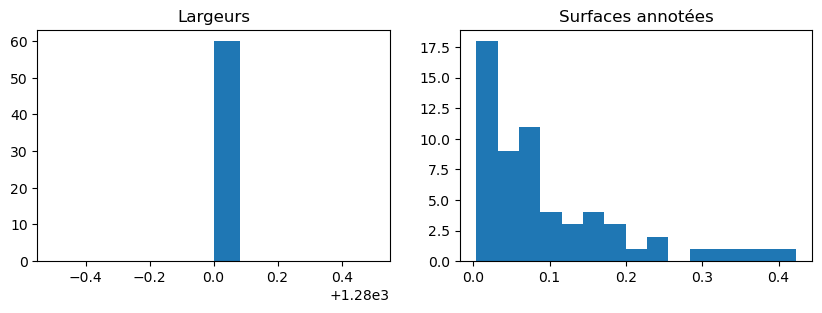

In [4]:
fig,axes=plt.subplots(3,3,figsize=(13,11))
for i,(_,r) in enumerate(df.head(3).iterrows()):
    rgb=np.array(Image.open(r.image).convert('RGB')); mask=np.array(Image.open(r['mask']))==2
    overlay=rgb.copy(); overlay[mask]=(0.45*overlay[mask]+0.55*np.array([255,40,40])).astype('uint8')
    for j,im in enumerate([rgb,mask,overlay]): axes[i,j].imshow(im,cmap='gray' if j==1 else None);axes[i,j].axis('off')
    axes[i,0].set_title(r['name'][:32]); axes[i,1].set_title('Masque anomalie=2');axes[i,2].set_title('Superposition')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(1,2,figsize=(10,3));ax[0].hist(df.width,bins=12);ax[0].set_title('Largeurs');ax[1].hist(df.area_ratio,bins=15);ax[1].set_title('Surfaces annotées');plt.show()

### Contrôle des sources apparentées et des duplications
Les noms d'images donnent parfois des indices sur la provenance ; **ce n'est pas une garantie d'indépendance**. Le notebook contrôle les doublons exacts et propose des comparaisons perceptuelles pour détecter les cas proches. Les groupes suspects doivent être inspectés avant de figer les splits.

In [5]:
def dhash(path):
    x=np.array(Image.open(path).convert('L').resize((9,8)))
    return (x[:,1:]>x[:,:-1]).flatten()
ph=[dhash(p) for p in df.image]
near=[]
for i in range(len(ph)):
    for j in range(i+1,len(ph)):
        d=int(np.count_nonzero(ph[i]!=ph[j]))
        if d<=5: near.append((df.iloc[i]['name'],df.iloc[j]['name'],d))
print('Paires dHash proches (à vérifier visuellement):',near[:25],'total',len(near))

Paires dHash proches (à vérifier visuellement): [] total 0


## 3. Data Preparation — séparation AVANT augmentation
La cible est le masque binaire `(labels_semantic == 2)`. La séparation est réalisée au niveau des images originales ; les transformations sont appliquées seulement sur le train. Les doublons exacts sont regroupés ; les images visuellement proches doivent être inspectées. Avec 60 images, les estimations sont très incertaines.

In [6]:
# Groupement par hash exact et par paires perceptuelles proches (union-find)
parents=list(range(len(df)))
def find(x):
    while parents[x]!=x: parents[x]=parents[parents[x]];x=parents[x]
    return x
def union(a,b): parents[find(a)]=find(b)
for i in range(len(df)):
    for j in range(i+1,len(df)):
        if hashlib.sha256(Path(df.iloc[i].image).read_bytes()).digest()==hashlib.sha256(Path(df.iloc[j].image).read_bytes()).digest() or np.count_nonzero(ph[i]!=ph[j])<=5:
            union(i,j)
df['group']=[find(i) for i in range(len(df))]
groups=df.group.unique(); tr_groups,te_groups=train_test_split(groups,test_size=.20,random_state=SEED)
tr_groups,va_groups=train_test_split(tr_groups,test_size=.20,random_state=SEED)
train_df=df[df.group.isin(tr_groups)].reset_index(drop=True)
val_df=df[df.group.isin(va_groups)].reset_index(drop=True)
test_df=df[df.group.isin(te_groups)].reset_index(drop=True)
assert not (set(train_df.group)&set(test_df.group) or set(train_df.group)&set(val_df.group) or set(val_df.group)&set(test_df.group))
print('Train/Validation/Test:',len(train_df),len(val_df),len(test_df))
OUT=Path('roadanomaly_results');OUT.mkdir(exist_ok=True)
for nm,t in [('manifest',df),('train',train_df),('validation',val_df),('test',test_df)]:t.to_csv(OUT/(nm+'.csv'),index=False)

Train/Validation/Test: 38 10 12


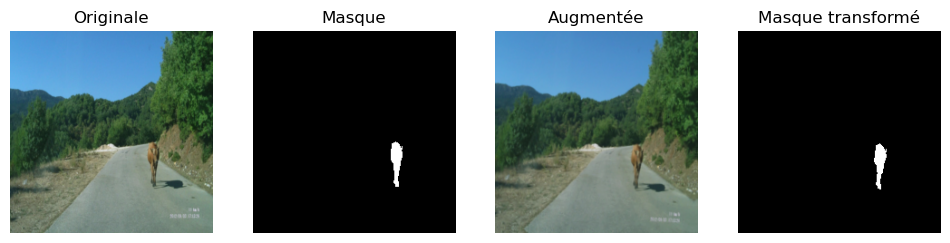

In [7]:
SIZE=224; BATCH=4 if DEVICE.type=='cuda' else 2
class RoadSeg(Dataset):
    def __init__(self,frame,augment=False): self.frame=frame.reset_index(drop=True);self.augment=augment
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        rgb=np.array(Image.open(r.image).convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR))
        mask=np.array(Image.open(r['mask']).resize((SIZE,SIZE),Image.Resampling.NEAREST))==2
        if self.augment:
            if random.random()<.5: rgb=np.fliplr(rgb).copy();mask=np.fliplr(mask).copy()
            if random.random()<.5:
                angle=random.uniform(-7,7);M=cv2.getRotationMatrix2D((SIZE/2,SIZE/2),angle,1)
                nr=cv2.warpAffine(rgb,M,(SIZE,SIZE),flags=cv2.INTER_LINEAR,borderMode=cv2.BORDER_REFLECT_101)
                nm=cv2.warpAffine(mask.astype('uint8'),M,(SIZE,SIZE),flags=cv2.INTER_NEAREST,borderMode=cv2.BORDER_CONSTANT,borderValue=0)>0
                if nm.any(): rgb,mask=nr,nm
            rgb=np.clip(rgb.astype('float32')*random.uniform(.85,1.15)+random.uniform(-12,12),0,255).astype('uint8')
        x=torch.from_numpy(rgb.copy()).permute(2,0,1).float()/255
        y=torch.from_numpy(mask.copy().astype('int64'))
        return x,y
train_loader=DataLoader(RoadSeg(train_df,True),batch_size=BATCH,shuffle=True,num_workers=0)
train_plain=DataLoader(RoadSeg(train_df),batch_size=BATCH,shuffle=False,num_workers=0)
val_loader=DataLoader(RoadSeg(val_df),batch_size=BATCH,shuffle=False,num_workers=0)
test_loader=DataLoader(RoadSeg(test_df),batch_size=1,shuffle=False,num_workers=0)
x0,y0=RoadSeg(train_df)[0];x1,y1=RoadSeg(train_df,True)[0]
fig,ax=plt.subplots(1,4,figsize=(12,3))
for a,im,title in zip(ax,[x0.permute(1,2,0),y0,x1.permute(1,2,0),y1],['Originale','Masque','Augmentée','Masque transformé']):a.imshow(im,cmap='gray' if 'Masque' in title else None);a.set_title(title);a.axis('off')
plt.show()

### Vérification de la Data Augmentation — démonstration reproductible
Les augmentations sont réalisées **à la volée** uniquement sur le train. Les masques restent alignés avec les images grâce à la même transformation géométrique et à l'interpolation *nearest neighbor*. Le test et la validation ne sont jamais augmentés. Les variantes affichées ne sont pas de nouvelles observations indépendantes.

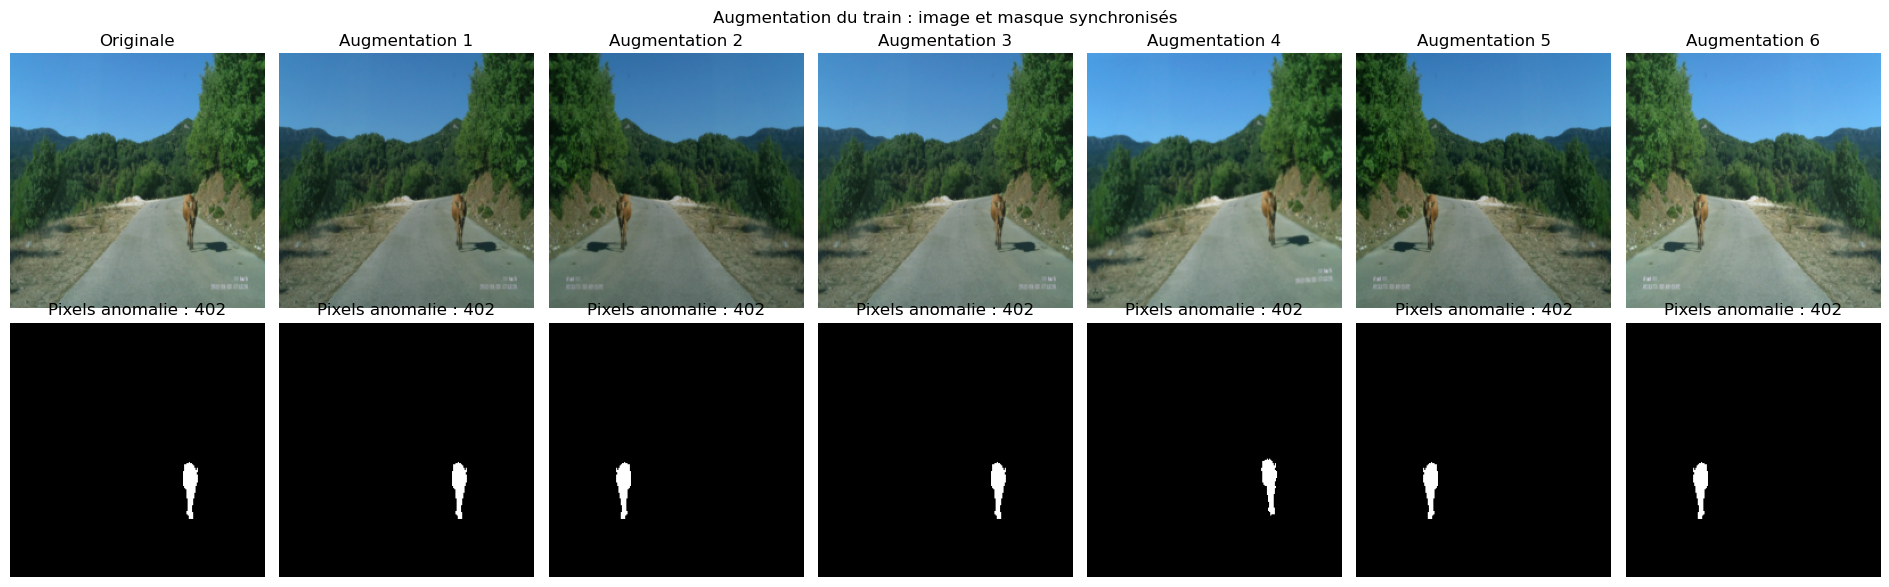

Augmentations FCN : flip horizontal p=0.5 ; rotation p=0.5, ±7° ; luminosité/contraste.
Validation et test : sans augmentation.


In [8]:
# Une image d'origine, six variantes augmentées et leurs masques.
assert len(train_df)>0, "Le train doit être créé avant cette cellule."
demo=RoadSeg(train_df.iloc[[0]],augment=True)
fig,axes=plt.subplots(2,7,figsize=(19,6))
orig_x,orig_y=RoadSeg(train_df.iloc[[0]],augment=False)[0]
for j in range(7):
    x,y=(orig_x,orig_y) if j==0 else demo[0]
    axes[0,j].imshow(x.permute(1,2,0).numpy())
    axes[1,j].imshow(y.numpy(),cmap='gray',vmin=0,vmax=1)
    axes[0,j].set_title('Originale' if j==0 else f'Augmentation {j}')
    axes[1,j].set_title(f'Pixels anomalie : {int(y.sum())}')
    for a in (axes[0,j],axes[1,j]):a.axis('off')
plt.suptitle('Augmentation du train : image et masque synchronisés')
plt.tight_layout();plt.show()
print('Augmentations FCN : flip horizontal p=0.5 ; rotation p=0.5, ±7° ; luminosité/contraste.')
print('Validation et test : sans augmentation.')


### Contrôle du déséquilibre des classes
Le nombre de pixels d'anomalie est mesuré séparément dans les trois partitions. Les poids de la fonction de perte sont calculés exclusivement sur le train.

In [9]:
balance=[]
for label,part in [('Train',train_df),('Validation',val_df),('Test',test_df)]:
    pixels=int(part['width'].mul(part['height']).sum())
    anomaly=int(part['anomaly_px'].sum())
    balance.append({'partition':label,'images':len(part),'pixels_anomalie':anomaly,
                    'pourcentage_anomalie':100*anomaly/max(1,pixels),
                    'images_sans_anomalie':int((part['anomaly_px']==0).sum())})
balance_df=pd.DataFrame(balance)
display(balance_df)
balance_df.to_csv(OUT/'class_balance.csv',index=False)


,partition,images,pixels_anomalie,pourcentage_anomalie,images_sans_anomalie
0,Train,38,3544962,10.122447,0
1,Validation,10,770102,8.356141,0
2,Test,12,1131349,10.229935,0


## 4. Modeling — trois expériences
**M1 : FCN à connexions multi-échelles, from scratch** ; **M2 : Mask R-CNN, from scratch** ; **M3 : FCN-ResNet50 avec poids ImageNet pour le backbone**. FCN et Mask R-CNN sont explicitement présentés dans le chapitre de segmentation. L'initialisation ImageNet ne constitue pas un autre dataset d'images routières : il s'agit toutefois d'un apprentissage externe préalable. **Si « aucune donnée externe » interdit aussi les poids pré-entraînés, l'expérience M3 n'est pas autorisée ; ne pas la présenter comme respectant cette contrainte.**

In [10]:
class ScratchFCN(nn.Module):
    # FCN multi-échelles : scores de couches profondes et intermédiaires, sans architecture U-Net.
    def __init__(self):
        super().__init__()
        self.b1=nn.Sequential(nn.Conv2d(3,24,3,padding=1),nn.ReLU(),nn.Conv2d(24,24,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.b2=nn.Sequential(nn.Conv2d(24,48,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.b3=nn.Sequential(nn.Conv2d(48,96,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.score2=nn.Conv2d(48,2,1);self.score3=nn.Conv2d(96,2,1)
    def forward(self,x):
        a=self.b1(x);b=self.b2(a);c=self.b3(b)
        scores=self.score2(b)+nn.functional.interpolate(self.score3(c),size=b.shape[-2:],mode='bilinear',align_corners=False)
        return nn.functional.interpolate(scores,size=x.shape[-2:],mode='bilinear',align_corners=False)
from torchvision.models.segmentation import fcn_resnet50
from torchvision.models.detection import maskrcnn_resnet50_fpn
m1=ScratchFCN()
print('FCN scratch:',sum(p.numel() for p in m1.parameters()))
# M3 : ne télécharger que les poids de backbone ResNet50 (ImageNet).
# La disponibilité réseau est testée lors de la cellule d'initialisation M3, sans substituer des poids aléatoires.

FCN scratch: 58156


In [11]:
def make_pretrained_fcn():
    from torchvision.models import ResNet50_Weights
    try:
        m=fcn_resnet50(weights=None,weights_backbone=ResNet50_Weights.IMAGENET1K_V1,num_classes=2,aux_loss=None)
        print('Backbone ImageNet chargé : transfert authentique')
        return m
    except Exception as e:
        print('TRANSFERT INDISPONIBLE :',repr(e));return None
# Décommenter lorsque les poids ImageNet sont autorisés et disponibles :
# m3=make_pretrained_fcn()
m3=None

### Mask R-CNN — cibles d'instances
On utilise en priorité les masques d'instances fournis dans l'archive (`labels_instance.png`). Leurs identifiants sont inspectés et les régions sont filtrées par intersection avec le masque sémantique d'anomalie. Le nombre d'instances n'est pas nécessairement identique au nombre d'objets physiques ; vérifier visuellement les exemples. Si le codage est incompatible, la cellule le signale et évite de fabriquer des annotations.

Masque instance: (720, 1280) uint8 valeurs (début): [0 1 2 3]


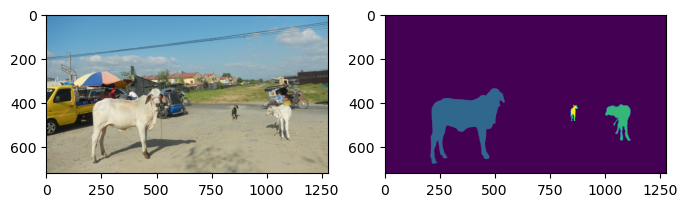

Instances de la première image: 1


In [12]:
# Certains fichiers n'ont pas de masque d'instances : on utilise
# alors les composantes connexes du masque sémantique, sans données externes.
instance_available = df[df['instance'].map(lambda p: Path(p).is_file())]
if len(instance_available):
    sample=np.array(Image.open(instance_available.iloc[0]['instance']))
else:
    sample=np.array(Image.open(df.iloc[0]['mask']))

print('Masque instance:',sample.shape,sample.dtype,'valeurs (début):',np.unique(sample)[:30])
fig,ax=plt.subplots(1,2,figsize=(8,3));ax[0].imshow(Image.open(instance_available.iloc[0].image if len(instance_available) else df.iloc[0].image));ax[1].imshow(sample);plt.show()
class RoadInstances(Dataset):
    def __init__(self,frame,augment=False):self.frame=frame.reset_index(drop=True);self.augment=augment
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        im=np.array(Image.open(r.image).convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR))
        sem=np.array(Image.open(r['mask']).resize((SIZE,SIZE),Image.Resampling.NEAREST))==2
        if Path(r['instance']).is_file():
            ins=np.array(Image.open(r['instance']).resize((SIZE,SIZE),Image.Resampling.NEAREST))
        else:
            _, ins=cv2.connectedComponents(sem.astype('uint8'), connectivity=8)
            ins=ins.astype('int32')
        if ins.ndim!=2:raise ValueError('Masque instance non indexé : vérifiez son codage')
        if self.augment:
            if random.random()<.5:
                im=np.fliplr(im).copy();sem=np.fliplr(sem).copy();ins=np.fliplr(ins).copy()
            if random.random()<.5:
                angle=random.uniform(-7,7)
                M=cv2.getRotationMatrix2D((SIZE/2,SIZE/2),angle,1)
                im=cv2.warpAffine(im,M,(SIZE,SIZE),flags=cv2.INTER_LINEAR,borderMode=cv2.BORDER_REFLECT_101)
                sem=cv2.warpAffine(sem.astype('uint8'),M,(SIZE,SIZE),flags=cv2.INTER_NEAREST,borderValue=0)>0
                ins=cv2.warpAffine(ins.astype('int32'),M,(SIZE,SIZE),flags=cv2.INTER_NEAREST,borderValue=0)
            im=np.clip(im.astype('float32')*random.uniform(.85,1.15)+random.uniform(-12,12),0,255).astype('uint8')
        masks=[];boxes=[]
        for idx in np.unique(ins):
            if idx == 0: continue  # 0 = fond, jamais une instance
            region=(ins==idx)&sem
            # Rejeter le fond ou une région couvrant presque tout le masque.
            if region.sum()<8 or region.sum()>=sem.sum()*.98 and len(np.unique(ins))>2:continue
            ys,xs=np.where(region)
            if len(xs)==0:continue
            x1,x2=xs.min(),xs.max()+1;y1,y2=ys.min(),ys.max()+1
            if x2-x1<2 or y2-y1<2:continue
            masks.append(region.astype('uint8'));boxes.append([x1,y1,x2,y2])
        if not masks and sem.any():
            # Fallback documenté : composantes connexes du masque sémantique.
            _,lab=cv2.connectedComponents(sem.astype('uint8'))
            for idx in np.unique(lab)[1:]:
                region=(lab==idx)
                if region.sum()<8:continue
                ys,xs=np.where(region);x1,x2=xs.min(),xs.max()+1;y1,y2=ys.min(),ys.max()+1
                if x2-x1>=2 and y2-y1>=2:masks.append(region.astype('uint8'));boxes.append([x1,y1,x2,y2])
        target={'boxes':torch.tensor(boxes,dtype=torch.float32).reshape(-1,4),'labels':torch.ones(len(boxes),dtype=torch.int64),'masks':torch.tensor(np.stack(masks) if masks else np.zeros((0,SIZE,SIZE),dtype='uint8'),dtype=torch.uint8),'image_id':torch.tensor([i])}
        return torch.from_numpy(im.copy()).permute(2,0,1).float()/255,target

def detection_collate(batch):return tuple(zip(*batch))
det_train=DataLoader(RoadInstances(train_df,True),batch_size=1,shuffle=True,collate_fn=detection_collate)
det_val=DataLoader(RoadInstances(val_df),batch_size=1,collate_fn=detection_collate)
# M2 : architecture Mask R-CNN complète sans poids pré-entraînés.
# Très coûteuse sur CPU ; entraînement recommandé sur GPU.
def make_scratch_maskrcnn():
    return maskrcnn_resnet50_fpn(weights=None,weights_backbone=None,num_classes=2,trainable_backbone_layers=5,min_size=SIZE,max_size=SIZE)
print('Instances de la première image:',len(RoadInstances(train_df)[0][1]['labels']))

### Entraînement FCN, checkpoints sélectionnés sur la validation
Les pertes sont pondérées sur le **train seulement** pour compenser les pixels d'anomalies rares. La validation choisit le checkpoint via Dice ; le test est réservé à l'évaluation finale. Les modèles sont réinitialisés à chaque expérience.

In [13]:
def metrics_binary(pred,gt):
    p=np.asarray(pred).astype(bool);g=np.asarray(gt).astype(bool)
    tp=np.logical_and(p,g).sum();fp=np.logical_and(p,~g).sum();fn=np.logical_and(~p,g).sum()
    return {'precision':float(tp/(tp+fp+1e-8)),'recall':float(tp/(tp+fn+1e-8)),'dice':float(2*tp/(2*tp+fp+fn+1e-8)),'iou':float(tp/(tp+fp+fn+1e-8))}

def eval_seg(model,loader,pretrained=False):
    model.eval();ps=[];gs=[];times=[]
    with torch.no_grad():
        for x,y in loader:
            x=x.to(DEVICE);t=time.perf_counter()
            logits=model(x)['out'] if pretrained else model(x)
            if DEVICE.type=='cuda':torch.cuda.synchronize()
            times.append((time.perf_counter()-t)/len(x))
            ps.extend(logits.argmax(1).cpu().numpy());gs.extend(y.numpy())
    met=metrics_binary(np.concatenate([a.ravel() for a in ps]),np.concatenate([a.ravel() for a in gs]));met['inference_ms']=1000*np.mean(times)
    return met,ps,gs

def fit_fcn(model,name,loader,epochs=8,pretrained=False):
    model.to(DEVICE)
    # Poids fixes calculés uniquement à partir du train (non augmenté).
    anomaly=sum(int((np.array(Image.open(p).resize((SIZE,SIZE),Image.Resampling.NEAREST))==2).sum()) for p in train_df['mask'])
    total=len(train_df)*SIZE*SIZE
    weight=min(20.,max(1.,(total-anomaly)/max(1,anomaly)))
    criterion=nn.CrossEntropyLoss(weight=torch.tensor([1.,weight],device=DEVICE))
    optim=torch.optim.AdamW(model.parameters(),lr=2e-4 if not pretrained else 5e-5)
    history=[];best=-1;patience=4;wait=0
    for ep in range(epochs):
        model.train();losses=[]
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            optim.zero_grad();logits=model(x)['out'] if pretrained else model(x)
            loss=criterion(logits,y);loss.backward();optim.step();losses.append(loss.item())
        met,_,_=eval_seg(model,val_loader,pretrained)
        history.append({'epoch':ep+1,'train_loss':np.mean(losses),**{'val_'+k:v for k,v in met.items()}})
        print(name,ep+1,'loss',round(np.mean(losses),4),'val Dice',round(met['dice'],4),'recall',round(met['recall'],4))
        if met['dice']>best+1e-5:
            best=met['dice'];wait=0;torch.save(model.state_dict(),OUT/(name+'.pt'))
        else:
            wait+=1
            if wait>=patience:break
    model.load_state_dict(torch.load(OUT/(name+'.pt'),map_location=DEVICE,weights_only=True))
    pd.DataFrame(history).to_csv(OUT/(name+'_history.csv'),index=False)
    return model,pd.DataFrame(history)
# RUN_TRAINING=True lance réellement les entraînements (GPU conseillé)
RUN_TRAINING=True # Mettre True pour lancer les 3 entraînements (GPU fortement recommandé)
if RUN_TRAINING:
    m1,h1=fit_fcn(ScratchFCN(),'fcn_scratch',train_loader,epochs=12)

fcn_scratch 1 loss 0.6931 val Dice 0.1641 recall 0.4642
fcn_scratch 2 loss 0.6816 val Dice 0.1418 recall 0.2691
fcn_scratch 3 loss 0.6702 val Dice 0.1589 recall 0.3465
fcn_scratch 4 loss 0.6536 val Dice 0.1551 recall 0.321
fcn_scratch 5 loss 0.6436 val Dice 0.229 recall 0.808
fcn_scratch 6 loss 0.6201 val Dice 0.2211 recall 0.6668
fcn_scratch 7 loss 0.6197 val Dice 0.2119 recall 0.5837
fcn_scratch 8 loss 0.587 val Dice 0.2004 recall 0.4697
fcn_scratch 9 loss 0.5689 val Dice 0.2292 recall 0.5703
fcn_scratch 10 loss 0.5844 val Dice 0.2097 recall 1.0
fcn_scratch 11 loss 0.6428 val Dice 0.2438 recall 0.6126
fcn_scratch 12 loss 0.5717 val Dice 0.2625 recall 0.6977


### Entraînement Mask R-CNN scratch
Les pertes internes de détection/segmentation sont utilisées. Le modèle produit des boîtes, scores et masques d'instances ; pour comparer à FCN, on agrège les masques prédits en une carte binaire. **Sans GPU, cette expérience peut prendre plusieurs heures.**

In [14]:
def maskrcnn_to_binary(pred,threshold=.5,score_threshold=.35):
    if len(pred['scores'])==0:return np.zeros((SIZE,SIZE),dtype=bool)
    keep=pred['scores']>=score_threshold
    if not keep.any():return np.zeros((SIZE,SIZE),dtype=bool)
    return (pred['masks'][keep,0]>=threshold).any(dim=0).cpu().numpy()

def eval_detection(model,frame):
    model.eval();ps=[];gs=[];times=[]
    with torch.no_grad():
        for i in range(len(frame)):
            x,_=RoadInstances(frame)[i];t=time.perf_counter()
            pred=model([x.to(DEVICE)])[0]
            if DEVICE.type=='cuda':torch.cuda.synchronize()
            times.append((time.perf_counter()-t)*1000)
            ps.append(maskrcnn_to_binary(pred))
            gs.append(np.array(Image.open(frame.iloc[i]['mask']).resize((SIZE,SIZE),Image.Resampling.NEAREST))==2)
    met=metrics_binary(np.concatenate([p.ravel() for p in ps]),np.concatenate([g.ravel() for g in gs]));met['inference_ms']=np.mean(times)
    return met,ps,gs

def fit_maskrcnn(epochs=3):
    model=make_scratch_maskrcnn().to(DEVICE)
    optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=1e-4)
    best=-1;history=[]
    for ep in range(epochs):
        model.train();losses=[]
        for xs,targets in det_train:
            xs=[x.to(DEVICE) for x in xs]
            targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
            if any(len(t['labels'])==0 for t in targets):continue
            optimizer.zero_grad();ld=model(xs,targets);loss=sum(ld.values())
            if not torch.isfinite(loss):continue
            loss.backward();optimizer.step();losses.append(loss.item())
        met,_,_=eval_detection(model,val_df)
        history.append({'epoch':ep+1,'train_loss':np.mean(losses) if losses else np.nan,**{'val_'+k:v for k,v in met.items()}})
        print('Mask R-CNN scratch',history[-1])
        if met['dice']>best:
            best=met['dice'];torch.save(model.state_dict(),OUT/'maskrcnn_scratch.pt')
    pd.DataFrame(history).to_csv(OUT/'maskrcnn_scratch_history.csv',index=False)
    model.load_state_dict(torch.load(OUT/'maskrcnn_scratch.pt',map_location=DEVICE,weights_only=True))
    return model,pd.DataFrame(history)
if RUN_TRAINING:
    m2,h2=fit_maskrcnn(epochs=3 if DEVICE.type=='cpu' else 8)

c:\Users\arije\anaconda3\Lib\site-packages\torchvision\models\detection\backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


Mask R-CNN scratch {'epoch': 1, 'train_loss': 4.097840472271568, 'val_precision': 0.0, 'val_recall': 0.0, 'val_dice': 0.0, 'val_iou': 0.0, 'val_inference_ms': 499.51935000135563}
Mask R-CNN scratch {'epoch': 2, 'train_loss': 1.83991077071742, 'val_precision': 0.0, 'val_recall': 0.0, 'val_dice': 0.0, 'val_iou': 0.0, 'val_inference_ms': 500.7672199921217}
Mask R-CNN scratch {'epoch': 3, 'train_loss': 1.5111667106026097, 'val_precision': 0.0, 'val_recall': 0.0, 'val_dice': 0.0, 'val_iou': 0.0, 'val_inference_ms': 430.0484200066421}


### Transfert learning FCN-ResNet50
L'architecture FCN est enseignée. Les poids pré-entraînés proviennent d'ImageNet et nécessitent un accès réseau ou un cache local. **Ils sont incompatibles avec une interdiction stricte de tout apprentissage externe** : dans ce cas, cette expérience est désactivée, et il est impossible de satisfaire simultanément « 1 modèle pré-entraîné » et « aucune connaissance externe ».

In [15]:
ALLOW_IMAGENET_WEIGHTS=True # Mettre True UNIQUEMENT si le professeur autorise des poids pré-entraînés
if RUN_TRAINING and ALLOW_IMAGENET_WEIGHTS:
    m3=make_pretrained_fcn()
    if m3 is not None:
        # Freeze backbone pour préserver les caractéristiques ImageNet.
        for p in m3.backbone.parameters():p.requires_grad=False
        m3,h3=fit_fcn(m3,'fcn_resnet50_imagenet',train_loader,epochs=8,pretrained=True)

Backbone ImageNet chargé : transfert authentique
fcn_resnet50_imagenet 1 loss 0.6458 val Dice 0.4139 recall 0.9689
fcn_resnet50_imagenet 2 loss 0.4401 val Dice 0.3041 recall 0.9777
fcn_resnet50_imagenet 3 loss 0.3826 val Dice 0.6618 recall 0.8342
fcn_resnet50_imagenet 4 loss 0.298 val Dice 0.5449 recall 0.9422
fcn_resnet50_imagenet 5 loss 0.289 val Dice 0.4469 recall 0.9703
fcn_resnet50_imagenet 6 loss 0.2676 val Dice 0.6475 recall 0.915
fcn_resnet50_imagenet 7 loss 0.2414 val Dice 0.5121 recall 0.9725


## 5. Evaluation — rappel, IoU, Dice, temps d'inférence
**Ne pas fabriquer de résultats :** les scores ci-dessous ne sont calculés que pour les checkpoints réellement présents. La comparaison exige le **même ensemble de test**. Un rappel élevé avec une faible précision signifie beaucoup de fausses alertes.

In [16]:
results={};predictions={}
for name,ctor,pre in [('FCN scratch',ScratchFCN,False),('FCN ResNet50 ImageNet',make_pretrained_fcn,True)]:
    ck=OUT/(('fcn_scratch' if not pre else 'fcn_resnet50_imagenet')+'.pt')
    if not ck.exists():continue
    model=ctor()
    if model is None:continue
    model.load_state_dict(torch.load(ck,map_location='cpu',weights_only=True));model.to(DEVICE)
    met,ps,gs=eval_seg(model,test_loader,pre)
    results[name]=met;predictions[name]=(ps,gs)
ck=OUT/'maskrcnn_scratch.pt'
if ck.exists():
    model=make_scratch_maskrcnn();model.load_state_dict(torch.load(ck,map_location='cpu',weights_only=True));model.to(DEVICE)
    met,ps,gs=eval_detection(model,test_df)
    results['Mask R-CNN scratch']=met;predictions['Mask R-CNN scratch']=(ps,gs)
if results:
    table=pd.DataFrame(results).T.sort_values('recall',ascending=False);display(table)
    table.to_csv(OUT/'test_metrics.csv')
else:print('Aucun checkpoint entraîné : lancer RUN_TRAINING=True, puis réexécuter cette cellule. Aucun score inventé.')

Backbone ImageNet chargé : transfert authentique


,precision,recall,dice,iou,inference_ms
FCN ResNet50 ImageNet,0.397644,0.740208,0.517359,0.348944,210.043108
FCN scratch,0.214676,0.496531,0.299753,0.176300,10.308158
Mask R-CNN scratch,0.000000,0.000000,0.000000,0.000000,402.404333


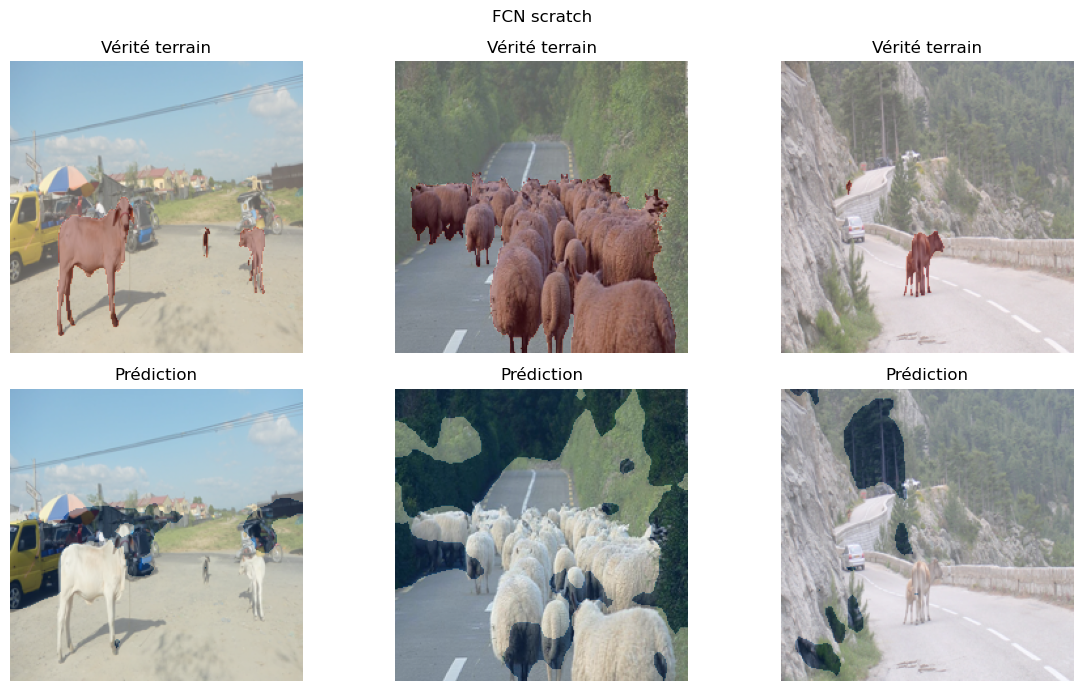

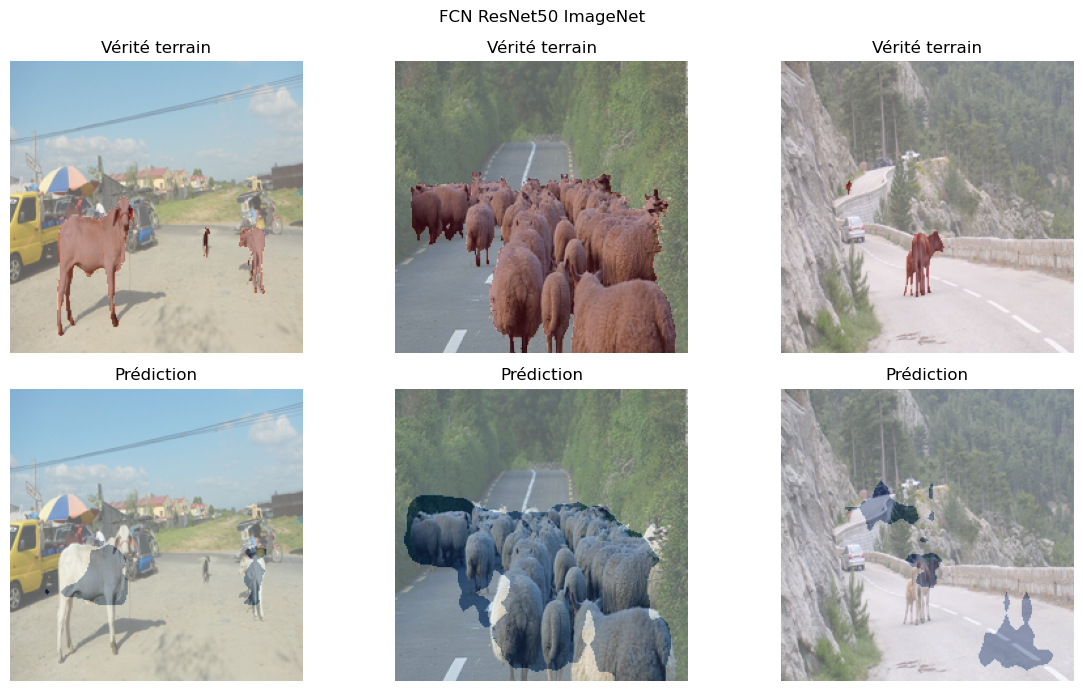

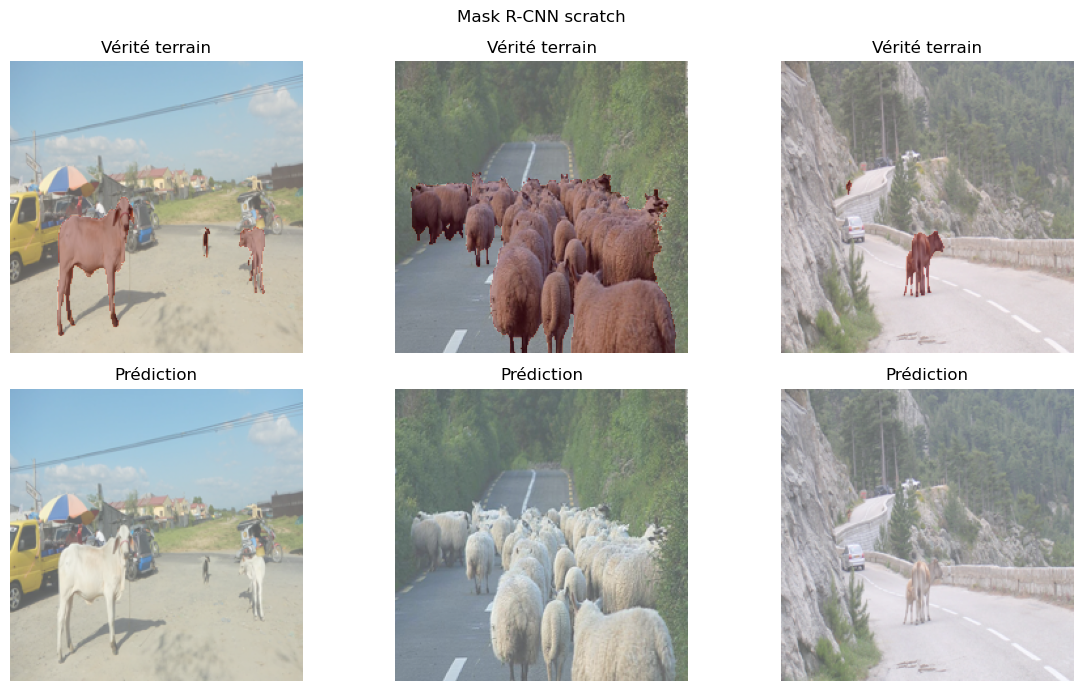

In [17]:
if predictions:
    for name,(ps,gs) in predictions.items():
        fig,axes=plt.subplots(2,min(3,len(ps)),figsize=(12,7))
        if len(ps)==1:axes=np.array(axes).reshape(2,1)
        for i in range(min(3,len(ps))):
            rgb=np.array(Image.open(test_df.iloc[i].image).convert('RGB').resize((SIZE,SIZE)))
            axes[0,i].imshow(rgb);axes[0,i].imshow(gs[i],alpha=.35,cmap='Reds');axes[0,i].set_title('Vérité terrain')
            axes[1,i].imshow(rgb);axes[1,i].imshow(ps[i],alpha=.35,cmap='Blues');axes[1,i].set_title('Prédiction')
            for ax in axes[:,i]:ax.axis('off')
        fig.suptitle(name);plt.tight_layout();plt.show()

## 6. Alertes visuelles et XAI
**Alerte illustrative :** un masque prédit contenant suffisamment de pixels déclenche un signal « anomalie possible ». Ce n'est **pas** une estimation du risque de collision. **XAI :** pour FCN, Grad-CAM sur les activations convolutionnelles par rapport au score d'anomalie ; pour Mask R-CNN, les masques et scores d'instances fournissent des éléments interprétables mais ne constituent pas à eux seuls une preuve causale. Le Grad-CAM de Mask R-CNN est plus complexe : la présente implémentation se limite au FCN et annonce explicitement cette limite.

In [18]:
def show_alert(image_path,model,pretrained=False,threshold=.01):
    rgb=np.array(Image.open(image_path).convert('RGB').resize((SIZE,SIZE)))
    x=torch.from_numpy(rgb.copy()).permute(2,0,1).float().unsqueeze(0).to(DEVICE)/255
    model.eval()
    with torch.no_grad():
        logits=model(x)['out'] if pretrained else model(x)
        prob=logits.softmax(1)[0,1].cpu().numpy()
    pred=prob>.5
    fig,ax=plt.subplots(figsize=(7,5));ax.imshow(rgb);ax.imshow(np.ma.masked_where(~pred,pred),alpha=.5,cmap='autumn')
    ax.set_title(('ALERTE VISUELLE : anomalie possible' if pred.mean()>threshold else 'Pas d’alerte détectée')+' — indicatif');ax.axis('off');plt.show()
    print('Surface prédite :',round(100*pred.mean(),2),'% ; seuil arbitraire de démonstration, non validé pour la conduite.')

def fcn_gradcam(model,image_path,target_layer,pretrained=False):
    activations=[];gradients=[]
    def forward_hook(_m,_in,out):activations.append(out)
    def backward_hook(_m,_gi,go):gradients.append(go[0])
    h1=target_layer.register_forward_hook(forward_hook)
    h2=target_layer.register_full_backward_hook(backward_hook)
    try:
        rgb=np.array(Image.open(image_path).convert('RGB').resize((SIZE,SIZE)))
        x=torch.from_numpy(rgb.copy()).permute(2,0,1).float().unsqueeze(0).to(DEVICE)/255
        model.eval();model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits=model(x)['out'] if pretrained else model(x)
            score=logits[:,1].mean();score.backward()
        a=activations[0].detach();g=gradients[0].detach()
        w=g.mean(dim=(2,3),keepdim=True);cam=torch.relu((w*a).sum(1,keepdim=True))
        cam=nn.functional.interpolate(cam,size=(SIZE,SIZE),mode='bilinear',align_corners=False)[0,0].cpu().numpy()
        cam=(cam-cam.min())/(cam.max()-cam.min()+1e-8)
        fig,ax=plt.subplots(1,2,figsize=(10,4));ax[0].imshow(rgb);ax[0].set_title('Image test');ax[1].imshow(rgb);ax[1].imshow(cam,cmap='jet',alpha=.45);ax[1].set_title('Grad-CAM — score anomalie')
        for a in ax:a.axis('off')
        plt.show();return cam
    finally:h1.remove();h2.remove()

# Exemple après entraînement :
# show_alert(test_df.iloc[0].image,m1)
# fcn_gradcam(m1,test_df.iloc[0].image,m1.b3[0])
# fcn_gradcam(m3,test_df.iloc[0].image,m3.backbone.layer4[-1].conv3,pretrained=True)

## 7. Conclusion générale — à compléter après les exécutions
Ce notebook met en place trois expériences de **segmentation d'anomalies** différentes de U-Net ResNet34 : FCN scratch, Mask R-CNN scratch et FCN avec backbone pré-entraîné. Il utilise exclusivement les **images et annotations routières de l'archive fournie**, avec augmentations réalisées seulement sur l'entraînement. Le troisième modèle exige toutefois des **poids ImageNet externes** : son usage doit être autorisé explicitement.

**État des preuves :** ne conclure sur le meilleur modèle qu'après entraînement, calcul du rappel, IoU, Dice et du temps d'inférence sur le test commun. Avec 60 images, les résultats sont exploratoires et ne démontrent pas une aptitude à la conduite réelle. Les Grad-CAM sont des explications visuelles approximatives, pas une preuve de compréhension des obstacles.

**Conseil de présentation :** comparer les exemples où les modèles ratent des anomalies et où ils déclenchent de fausses alertes ; ne pas sélectionner un modèle uniquement parce qu'il maximise le rappel en marquant toute l'image comme anormale.

## 8. Diagnostic des apprentissages
Les courbes sont tracées à partir des historiques réellement enregistrés ; elles aident à détecter l'absence de progression ou un surapprentissage. Elles ne sont pas des scores inventés.

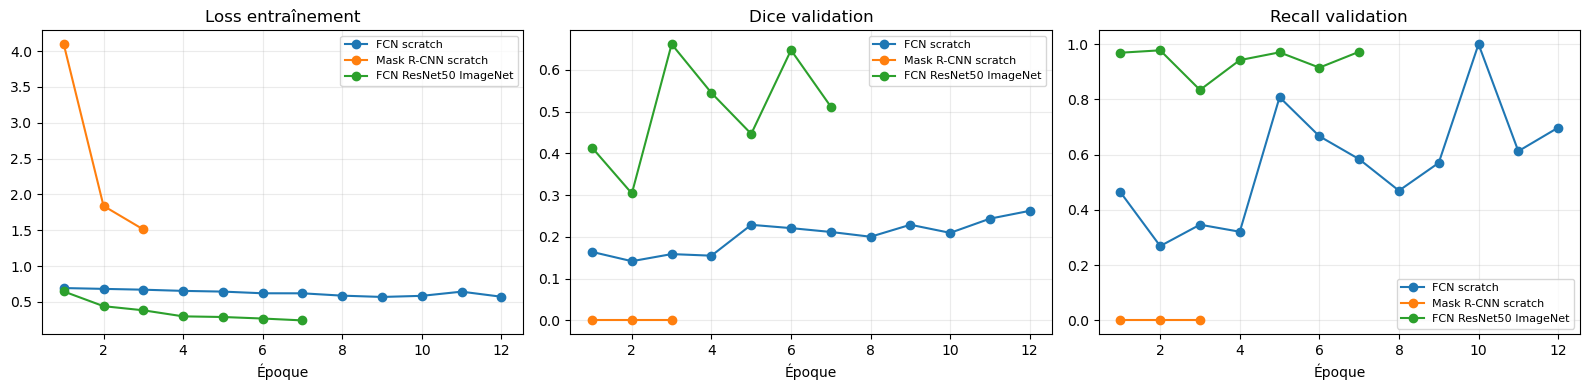

In [19]:
history_files={
    'FCN scratch':OUT/'fcn_scratch_history.csv',
    'Mask R-CNN scratch':OUT/'maskrcnn_scratch_history.csv',
    'FCN ResNet50 ImageNet':OUT/'fcn_resnet50_imagenet_history.csv'
}
fig,axs=plt.subplots(1,3,figsize=(16,4))
found=False
for name,path in history_files.items():
    if not path.exists():continue
    hist=pd.read_csv(path);found=True
    axs[0].plot(hist['epoch'],hist['train_loss'],marker='o',label=name)
    axs[1].plot(hist['epoch'],hist['val_dice'],marker='o',label=name)
    axs[2].plot(hist['epoch'],hist['val_recall'],marker='o',label=name)
for a,title in zip(axs,['Loss entraînement','Dice validation','Recall validation']):
    a.set_title(title);a.set_xlabel('Époque');a.grid(alpha=.25)
    if found:a.legend(fontsize=8)
if found:plt.tight_layout();plt.show()
else:
    plt.close(fig)
    print('Aucun historique disponible : activer RUN_TRAINING et exécuter les cellules d’entraînement.')


## 9. Analyse des erreurs sur le test (diagnostic, sans réglage des hyperparamètres)
Les faux négatifs représentent des pixels d'anomalie non détectés ; les faux positifs représentent des alertes erronées. Les métriques par image permettent de repérer les situations difficiles. **Le test ne doit jamais servir à choisir les paramètres ou les seuils.**

In [20]:
if predictions:
    for name,(ps,gs) in predictions.items():
        rows=[]
        for idx,(pred,gt) in enumerate(zip(ps,gs)):
            met=metrics_binary(pred,gt)
            met.update({'image':test_df.iloc[idx]['name'],
                        'pixels_faux_negatifs':int(np.logical_and(~np.asarray(pred,dtype=bool),np.asarray(gt,dtype=bool)).sum()),
                        'pixels_faux_positifs':int(np.logical_and(np.asarray(pred,dtype=bool),~np.asarray(gt,dtype=bool)).sum())})
            rows.append(met)
        errors=pd.DataFrame(rows).sort_values('pixels_faux_negatifs',ascending=False)
        filename=name.lower().replace(' ','_').replace('-','_')
        errors.to_csv(OUT/f'{filename}_errors_per_image.csv',index=False)
        print('\n',name,'— exemples les plus difficiles (faux négatifs) :')
        display(errors.head(5))
else:
    print('Entraîner et évaluer les modèles pour obtenir une analyse des erreurs.')



 FCN scratch — exemples les plus difficiles (faux négatifs) :


,precision,recall,dice,iou,image,pixels_faux_negatifs,pixels_faux_positifs
1,0.183678,0.189605,0.186594,0.102897,animals06_sheep_roads_lambs.webp,14968,15564
10,0.000000,0.000000,0.000000,0.000000,obstacles12_rocks4.webp,3166,50
0,0.041888,0.073069,0.053249,0.027353,animals01_Guiguinto_railway_station_Calves.webp,3108,5604
7,0.134985,0.294910,0.185201,0.102050,obstacles05_cardboard_czech_hedgehog.webp,2618,7017
3,0.210196,0.562076,0.305971,0.180617,animals14_Dekemhare_Road.webp,2194,10581



 FCN ResNet50 ImageNet — exemples les plus difficiles (faux négatifs) :


,precision,recall,dice,iou,image,pixels_faux_negatifs,pixels_faux_positifs
8,0.504216,0.613688,0.553592,0.382735,obstacles07_czech_hedgehog.webp,4781,7468
11,0.938150,0.514493,0.664542,0.497614,vehicle01_man_carrying_dry_grass_on_bicycle.webp,3149,220
1,0.891089,0.886844,0.888961,0.800117,animals06_sheep_roads_lambs.webp,2090,2002
5,0.188864,0.231722,0.208109,0.116139,cones06_VnA_traffic_cones.webp,1923,2491
0,0.814337,0.470922,0.596750,0.425263,animals01_Guiguinto_railway_station_Calves.webp,1774,360



 Mask R-CNN scratch — exemples les plus difficiles (faux négatifs) :


,precision,recall,dice,iou,image,pixels_faux_negatifs,pixels_faux_positifs
1,0.0,0.0,0.0,0.0,animals06_sheep_roads_lambs.webp,18470,0
8,0.0,0.0,0.0,0.0,obstacles07_czech_hedgehog.webp,12376,0
11,0.0,0.0,0.0,0.0,vehicle01_man_carrying_dry_grass_on_bicycle.webp,6486,0
3,0.0,0.0,0.0,0.0,animals14_Dekemhare_Road.webp,5010,0
7,0.0,0.0,0.0,0.0,obstacles05_cardboard_czech_hedgehog.webp,3713,0


## 10. Expérience d'ablation : FCN scratch sans augmentation vs avec augmentation
L'ablation permet de démontrer **l'effet réel** de la Data Augmentation. Elle est **facultative**, car elle entraîne un quatrième *run expérimental* du **même modèle FCN scratch**, sans introduire une quatrième architecture. La comparaison utilise la même séparation et le même protocole de validation. Le test reste réservé à l'évaluation finale.

In [21]:
# Lancer seulement si le temps de calcul le permet.
RUN_AUGMENTATION_ABLATION=False
if RUN_AUGMENTATION_ABLATION:
    # fit_fcn sélectionne le meilleur checkpoint sur la validation.
    # Sauvegarde sous un nom distinct pour préserver le modèle principal.
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    model_noaug,h_noaug=fit_fcn(ScratchFCN(),'fcn_scratch_noaug',train_plain,epochs=12)
    if (OUT/'fcn_scratch_history.csv').exists():
        h_aug=pd.read_csv(OUT/'fcn_scratch_history.csv')
        comparison=pd.DataFrame([
            {'experience':'Avec augmentation','meilleur_dice_validation':h_aug['val_dice'].max(),
             'meilleur_recall_validation':h_aug['val_recall'].max()},
            {'experience':'Sans augmentation','meilleur_dice_validation':h_noaug['val_dice'].max(),
             'meilleur_recall_validation':h_noaug['val_recall'].max()}
        ])
        display(comparison)
        comparison.to_csv(OUT/'ablation_augmentation_validation.csv',index=False)
else:
    print('Ablation non exécutée. Mettre RUN_AUGMENTATION_ABLATION=True pour comparer les deux entraînements.')


Ablation non exécutée. Mettre RUN_AUGMENTATION_ABLATION=True pour comparer les deux entraînements.


## 11. Limites et points à défendre à l'oral
- **Petit échantillon :** 60 images originales ; les augmentations ne créent pas de scènes indépendantes.
- **Indépendance :** les groupes de doublons visuels sont séparés avant augmentation ; des scènes apparentées non détectées peuvent subsister.
- **Mask R-CNN :** les masques d'instances manquants sont approximés par composantes connexes, ce qui n'est pas une annotation manuelle de référence.
- **Comparabilité :** même test et mêmes métriques de segmentation pour les trois modèles ; les budgets d'époques et le pré-entraînement diffèrent et doivent être explicités.
- **Sécurité :** un bon Dice ne garantit pas une détection fiable en conduite réelle ; analyser particulièrement le Recall et les faux négatifs.
- **Reproductibilité :** seed, partitions CSV, historiques, checkpoints et résultats sont conservés dans `roadanomaly_results/`.
